In [ ]:
import pandas as pd                 # Data tables
import os                           # Returns current directory, create files
import numpy as np                  # Arrays
import matplotlib.pyplot as plt	    # Graphs

from math import sqrt, atan, log, exp, sin, cos, tan, trunc

from scipy.integrate import odeint
from scipy.integrate import solve_ivp
from scipy.optimize import *
from scipy import interpolate

import matplotlib.dates as mdates

from simulation_INTERFACE_261001 import *
from simulation_MATERIALS_261001 import *
from simulation_PREPRO_261001 import *
from simulation_SIM_261001 import *
from simulation_VISUALIZATION_261001 import *
from simulation_WEATHER_261001 import *

pd.options.display.max_columns = 999
np.set_printoptions(threshold=np.inf, linewidth=200)
np.set_printoptions(suppress=True) # avoid scientific notation

# Data

In [ ]:
project = '291001_TVVL_restaurant'

In [ ]:
# Postal code
CP = 1000

# Internal temperature set points
t_set_heating  = 20 # Temperature setpoint during occupancy

# Infiltration rate at 50 Pa
n_50 = 1.0

# Windows U-value
U_wd = 1.50  #[W/m2/K]

#### Hourly schedules

In [ ]:
hourly_data = \
[('occupancy',   (0, 0, 0, 0, 0, 0, 0, 0.1, 0.3, 0.7, 0.3, 0.3, 1.0, 1.0, 0.3, 0.7,  0.3, 0.1, 0, 0, 0, 0, 0, 0) ),
 ('ventilation', (0, 0, 0, 0, 0, 0, 0,   1,   1,   1,   1,   1,   1,   1,   1,   1,    1,   1, 0, 0, 0, 0, 0, 0) )
]

# Create the DataFrame
dfh = pd.DataFrame({name: values for name, values in hourly_data})
dfht= dfh.T

# Rename the columns as strings '1' to '24'
dfht.columns = [str(i) for i in range(1, 25)]

In [ ]:
# Prepare subplots
nplots = len(dfht)
colors = ['tab:blue', 'tab:green', 'tab:red', 'tab:blue', 'tab:cyan']
fig, axes = plt.subplots(nplots, 1, figsize=(5, 3), sharex=True)
axes = axes.flatten()     # ensure axes is a flat list

hours = range(1, 25)

# Plot all rows as separate vertical bar plots
for ax, (name, row), color in zip(axes, dfht.iterrows(), colors):
    ax.bar(hours, row.values, color = color)
    ax.set_title(name)
    ax.set_xlim(1, 24)
    ax.set_ylim(0, max(row.values) + 0.1)
    ax.set_ylabel("Value")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add x-axis label only on the last subplot
axes[-1].set_xlabel("Hour of day")
axes[-1].set_xticks(hours)

plt.tight_layout()
plt.show()

#### Control

In [ ]:
# Ventilation
CO2_vent_control   = True # Fresh air supply controlled by CO2 probe

# Heating set back
t_set_min          = 15 # Temperature setpoint during unoccupancy 
WEEK_END_set_back  = True # Unoccupancy and set back of the system during the week-end

# Heating restart
nh_ti_rh    = 0.5 # 1       # number of reheating hours per °C difference when t_set_heating et t_in
nh_te_rh    = 1/6    # number of reheating hours per °C difference when ext temperature < t_e_base

#### Zone dimensions

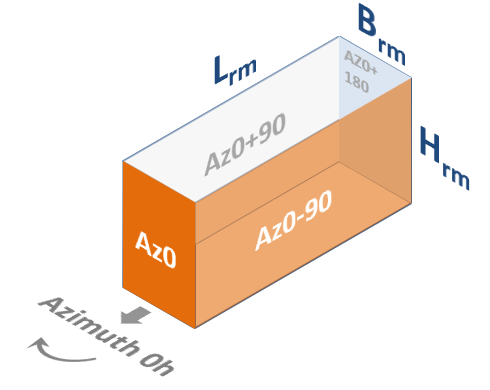

In [ ]:
# Azimuth of the reference 0h vertical external wall in deg  (South = 0, West = 90, North = 180, East = -90)
azimuth_0h_deg = 0

# L: Lenght, B : Breadth, H : Height [m]

L_in = 3.6 * 4
B_in = 11.40
H_in = 3.01

A_floor = L_in * B_in

t_roof  = 0.50
t_floor = 0.37

L_rm = L_in + 0.40
B_rm = B_in + 0.35 + 0.40
H_rm = H_in + t_roof + t_floor/2 

f_temp_min, f_temp_avg = temperature_factors(CP, we)

lst_room = [azimuth_0h_deg, L_in, B_in, H_in, A_floor, L_rm, B_rm, H_rm,  
            n_50, U_wd, f_temp_min, f_temp_avg ] 

#### Ventilation

In [ ]:
# Occupants requirements
q_occ_m3h  = 45 # Fresh air flow per occupant(m³/h.occ)

# Floor area per occupant
A_fl_occ = 10 # Office value: A supplementary AHU will be added

# Number of occupants
n_occ      = A_floor / A_fl_occ  # Number of occupants

qv_su_m3h   = n_occ * q_occ_m3h # ventilation fan supply air flow  (m³/h)
qv_ex_m3h   = n_occ * q_occ_m3h # ventilation fan extracted air flow  (m³/h)
epsilon_hx  = 0.80 # efficiency of ventilation system heat recovery exchanger

#### Materials

In [ ]:
materials_list = []

materials_list.append({"material":'concrete_bloc'      ,"lambda":1.36,"rho":2000,"c":1000})
materials_list.append({"material":'insulation'         ,"lambda":0.026,"rho":80, "c":840})
materials_list.append({"material":'reinforced_concrete',"lambda":2.30,"rho":2400,"c":1000})
materials_list.append({"material":'concrete'           ,"lambda":2.10,"rho":2400,"c":1000})
materials_list.append({"material":'brick'              ,"lambda":1.59,"rho":2200,"c":1000})
materials_list.append({"material":'screed'             ,"lambda":1.40,"rho":2000,"c":1000})
materials_list.append({"material":'foamglass'          ,"lambda":0.055,"rho":150,"c":1000})

materials = pd.DataFrame(materials_list)

#### Wall types layers

In [ ]:
wt_layers = \
[('wall_ext', 0, 0.190, 'concrete_bloc'),
 ('wall_ext', 1, 0.100, 'insulation'),
 
 ('wall_sep', 0, 0.190, 'concrete_bloc'),
 
 ('roof'    , 0, 0.300, 'reinforced_concrete'),
 ('roof'    , 1, 0.200, 'insulation'),

 ('floor_sep_u', 0, 0.070, 'screed'),
 ('floor_sep_u', 1, 0.300, 'concrete')

]

 # ('floor_sep_u', 0, 0.060, 'screed'),
 # ('floor_sep_u', 1, 0.065, 'insulation'),
 # ('floor_sep_u', 2, 0.300, 'concrete')

wt_layers = pd.DataFrame(wt_layers, columns=('wall_type', 'layer', 'thickness', 'material'))
wt_layers = wt_layers.sort_values(['wall_type', 'layer'])
wt_layers = wt_layers.set_index('wall_type')

# Wall thicknesses
dftk = wt_layers.groupby(level='wall_type')['thickness'].sum().reset_index()
thk = dict(zip(dftk['wall_type'], dftk['thickness']))
df_thk = pd.DataFrame(list(thk.items()), columns=['wall_type', 'thickness']).set_index('wall_type')

t_floor = thk['floor_sep_u']
t_roof  = thk['roof']

display(df_thk.T)

#### Walls temperatures and heating powers
't_ext' : external  
't_int' : to conditioned space   
't_min' : to unconditioned space at t_min  
't_avg' : to unconditioned space at t_avg   

In [ ]:
# Facades
# Facade name, wall type, environmental temperature name, radiant heating power [W/m2]

walls = \
[('az0'         , 'wall_ext' ,  't_ext', 0),
 ('az0+90'      , 'wall_ext' ,  't_ext', 0),
 ('az0+180'     , 'wall_sep' ,  't_int', 0),
 ('az0-90'      , 'wall_ext' ,  't_ext', 0),
 ('floor'       , 'floor_sep_u','t_int', 0),
 ('ceiling/roof', 'roof'  ,     't_ext', 0)]

#!!! display orientation string
wl0 = pd.DataFrame(walls, columns=('azimuth',  'wall_type', 't_env_name', 'rad heating [W/m2]')).set_index('azimuth')
wl = dfwl_final(wl0, azimuth_0h_deg)

wl

#### Convective heating power

In [ ]:
# Installed specific convective heating power (W/m² floor area)
qc_heating  = 100 # W/m²

In [ ]:
# Store the system data in a list
lst_syst= [t_set_heating, t_set_min,
           q_occ_m3h, n_occ, qc_heating,  
           qv_su_m3h, qv_ex_m3h,  epsilon_hx, 
           nh_ti_rh, nh_te_rh, WEEK_END_set_back, CO2_vent_control] 

#### Walls framed in the main vertical walls

In [ ]:
# Walls set in the facade walls
# facade, wall type, breadth, height, sill height, dist corner,
# environmental temperature name, radiant heating power [W/m2]
datawi = \
[('az0+180', 'no' , 6.00, 3.01,  t_floor/2, 11.40 - 9 + 0.35, 't_int', 0)]

wi0 = pd.DataFrame(datawi, columns=('azimuth',  'wall_type', \
                                   'breadth [m]', 'height [m]', 'sill height [m]', 'dist corner [m]', \
                                   't_env_name', 'rad heating [W/m2]')).set_index('azimuth')
# wi0

wi = dfwi_final(wi0, azimuth_0h_deg, wl, L_rm, B_rm, H_rm)
wi

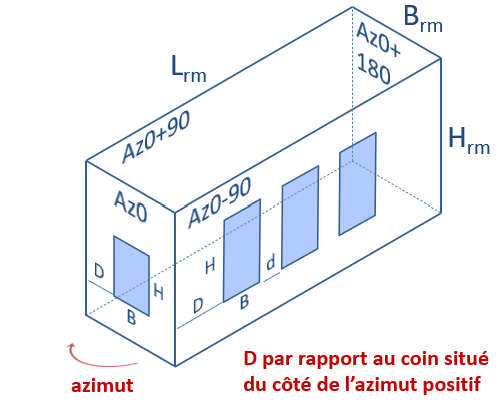

#### Windows

In [ ]:
lst_cols = \
['azimuth', 'number', 'breadth [m]', 'height [m]', 'sill height [m]', 'dist corner [m]', 'dist windows [m]']

H_wd_1 = 3.01
sill_wd_1 = t_floor/2

H_wd_2 = 0.8
sill_wd_2 = 0.8

datawd = \
[(   'az0',    1, 11.80, H_wd_1, sill_wd_1,  0., 0.),
 (   'az0+90', 1, L_rm,  H_wd_1, sill_wd_1,  0., 0.),
 (   'az0-90', 4, 1.80,  H_wd_2, sill_wd_2, 1.3, 1.80)
]

wd0 = pd.DataFrame(datawd, columns=lst_cols ).set_index('azimuth')
# wd0

wd = dfwd_final(wd0, azimuth_0h_deg, wl, L_rm, B_rm, H_rm)
wd

#### 3D view

In [ ]:
room, wallsint, windows = create_room_windows(L_rm, B_rm, H_rm, wi, wd)
fig = go.Figure(data=[room] + wallsint + windows)


# fig.update_layout(
#     width=1500,   # pixels
#     height=700,   # pixels
#     scene=dict(
#         xaxis_title='X',
#         yaxis_title='Y',
#         zaxis_title='Z',
#         aspectmode='data',
#     ),
#     title= project 
# )

# fig.show()

#### Weather simulation data
'CW' : a cold wave example (1 month)   
'MW'  : a mean January (1 month)

In [ ]:
weather = 'CW'

# Weather data
w = weather_data(weather)

# Simulation

In [ ]:
%%time

# df : data
# dfi : intermittent heating results
# dfc : continuous heating results

df, dfi, dfc = sim(weather, lst_room, lst_syst, dfh, w, wl, wi, wd, wt_layers, materials)

In [ ]:
balance = check_balance(dfi, 900)
balance.astype(int)

# Results

#### Energy demands vs Comfort

In [ ]:
Emax = 35
Estep = 5
pmax = 105 
pstep = 15

# Energy savings
DQ_pct = int(100 * (dfc['Qh_kWhm2'].iloc[-1] - dfi['Qh_kWhm2'].iloc[-1]) / (dfc['Qh_kWhm2'].iloc[-1] + 0.0000001))

fig, ax1 = plt.subplots(figsize=(6, 4))

day = dfi['ts'] / 3600 / 24

ax1.set_xlabel('Day')

ax1.set_ylabel('Energy demand [kWh/m2]', color='k') 
ax1.plot(day, dfc.Qh_kWhm2, color='tab:orange',  linewidth = 3, label = 'Energy Continuous')
ax1.plot(day, dfi.Qh_kWhm2, color='tab:orange',  linewidth = 3, linestyle = 'dotted', \
         label = 'Energy Intermittent')

ax1.set_ylim(0, 1.3 * Emax)
ax1.set_yticks(np.arange(0, Emax + 0.1, step = Estep))
ax1.tick_params(axis='y', labelcolor='k')
ax1.grid(linestyle ='dotted')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
plt.xticks(np.arange(0, int(day.iloc[-1]) + 1, 7))

ax2.set_ylabel('Discomfort time percentage [%]', color='k')
ax2.plot(day, 100 * dfc.fr_overcool, color='tab:blue', linewidth = 3, label = 'Overcooling Continuous')
ax2.plot(day, 100 * dfi.fr_overcool, color='tab:blue', linewidth = 3, linestyle = 'dotted', \
         label = 'Overcooling Intermittent')

ax2.set_ylim(0, 1.3 * pmax)
ax2.set_yticks(np.arange(0, pmax + 0.000001, step = pstep))
ax2.tick_params(axis='y', labelcolor='k')
ax2.legend(loc='upper right')

ax2.text(0.35, 0.77, 'Energy Savings : ' + str(DQ_pct ) + ' %', \
         horizontalalignment='right', verticalalignment='bottom', transform=ax2.transAxes);


fig.tight_layout()  
plt.title( project + ' - ' +  weather_name(weather))
plt.show()

#### Temperature and heating power

In [ ]:
dfr = dfi.copy()

if weather == 'CW' :
    lst_start_plot = ['1996-12-19 00:00:00']
    lst_stop_plot  = ['1997-01-10 00:00:00']

if weather == 'MW' :
    lst_start_plot = ['2005-01-01 00:00:00']
    lst_stop_plot  = ['2005-01-31 00:00:00']
    
for iplot in range(len(lst_start_plot)):
    
    start = pd.to_datetime(lst_start_plot[iplot])
    stop  = pd.to_datetime(lst_stop_plot[iplot]) 
    
    mask = (dfr.index >= start) & (dfr.index <= stop)

    dfr_plot = dfr.loc[mask].copy()
    
    day = dfr_plot.index
    
    fig, ax1 = plt.subplots(figsize=(20, 4), constrained_layout=True)

    # Define temperature and power limits
    T_min, T_max, T_step = (-15, 30.1, 5) if weather != 'HW' else (5, 40.1, 5) 
    Q_min, Q_max, Q_step = (0, 181, 20) 
    
    # Temperature plots
    plot_temperature(ax1, day, dfr_plot, \
                     curves=["t_set_h", "t_out", "t_in"], \
                     colors=['tab:blue',  'tab:grey', 'tab:blue'], \
                     linestyles = ['dotted',   'dotted', 'solid'])
    
    if WEEK_END_set_back:
        ax1.fill_between(day, T_min * np.ones(len(day)), \
                     T_min + (dfr_plot.index.dayofweek >= 5) * (T_max - T_min), \
                     color='tab:blue', alpha=0.2, label = 'week-end' )

    # Fill between t_i and t_set where t_i < t_set
    mask_fill = (dfr_plot["t_in"] < dfr_plot["t_set_h"]) & (dfr_plot["f_occ"] > 0)
    ax1.fill_between(
        day,
        dfr_plot["t_in"],
        dfr_plot["t_set_h"],
        where=mask_fill,
        interpolate=True,
        alpha=0.3,
        color="orange"
    )

    
    ax1.set_ylim(T_min, T_max)
    ax1.set_yticks(np.arange(T_min, T_max, step=T_step))
    ax1.legend(ncol=8, fontsize=10, loc='upper left')
    
    # X-tick configuration
    configure_ticks(ax1, start, stop)
    
    # Power plots (twin axis)
    ax2 = ax1.twinx()
    plot_power(ax2, day, dfr_plot, \
               curves=["Q_dot_h_Wm2"], \
               colors=['tab:red','tab:blue'], \
               linestyles = ['solid', 'solid'], rolling_span = 1)
    
    ax2.set_ylim(Q_min, Q_max)
    ax2.set_yticks(np.arange(Q_min, Q_max, step=Q_step))
    ax2.legend(ncol=5, fontsize=10, loc='upper right')
    
    # Title and display
    plt.title(
        f"{project} - {weather_name(weather)}  : {start.strftime('%d-%m-%Y')} / {stop.strftime('%d-%m-%Y')}"
    )

    plt.grid(linestyle='dotted')
    plt.show()

#### Weekly graph

In [ ]:
# ================================================================
# Interactive week selection
# ================================================================

from ipywidgets import interact, IntSlider, Layout

min_week = 0

if weather == 'CW':
    max_week = int(len(df) / (24 * 4 * 7) - 1)
    slider_layout = Layout(width='300px')
    title = 'Cold wave : 19/12/1996 - 10/01/1997'

if weather == 'MW':
    max_week = int(len(df) / (24 * 4 * 7) - 2)
    slider_layout = Layout(width='1000px')
    title = 'Mean January : 01/01/2005 - 31/01/2005'


def interactive_plot(iweek_start):

    # ------------------------------------------------------------
    # Number of 15-minute samples in one week
    # ------------------------------------------------------------
    n_week = 7 * 24 * 4       # 672

    # ------------------------------------------------------------
    # Original row corresponding to the selected week
    # ------------------------------------------------------------
    irow = 2 + 2 * 24 + iweek_start * n_week

    # ------------------------------------------------------------
    # Find the Monday containing this date
    # ------------------------------------------------------------
    start = df.index[irow]

    # Monday 00:00
    start = (
        start
        .normalize()
        - pd.Timedelta(days=start.weekday())
    )

    # Following Monday 00:00
    stop = start + pd.Timedelta(days=7)

    plot_weekly_data(dfr, title, start, stop)


interact(
    interactive_plot,
    iweek_start=IntSlider(
        min=min_week,
        max=max_week,
        step=1,
        value=min_week,
        layout=slider_layout
    )
);

#### Daily graph

In [ ]:
from ipywidgets import DatePicker, Output
from IPython.display import display, clear_output

import datetime
from datetime import timedelta
from datetime import timezone
from datetime import time

import matplotlib.dates as mdates

if weather == 'CW' :
    min_date = datetime.date(1996, 12, 19)
    max_date = datetime.date(1997,  1, 10)
    title = 'Cold wave : 19/12/1996 - 10/01/1997'

if weather == 'MW' :
    min_date = datetime.date(2004, 9, 1)
    max_date = datetime.date(2005, 6, 10)
    title = 'Mean January : 01/01/2005 - 31/01/2005'


# Create a DatePicker widget
date_picker1 = DatePicker(
    description='Select Date:',
    disabled=False,
    value=datetime.date.today(),
    min=min_date,
    max=max_date
)

# Create an Output widget to display the plot
output1 = Output()

# Function to generate and display a plot based on the selected date
def on_date_change1(change):
    with output1:
        clear_output(wait=True)  # Clear previous plot
        start_date = change['new']

        start = start_date
        stop = start_date + timedelta(days=1)

        start = pd.to_datetime(start)
        stop = pd.to_datetime(stop)

        plot_daily_data(dfr, title, start, stop)

# Connect the function to the widget's value change
date_picker1.observe(on_date_change1, names='value')

# Display the widget and output
display(date_picker1)
display(output1)

# Trigger initial plot
on_date_change1({'new': date_picker1.value})